
![logo Itq](img/ITQ.png)
# Práctica resuelta: normalización, estandarización, detección de outliers e imputación de datos ausentes con CRISP-DM
**Asignatura:** Fundamentos de Machine Learning  
**Docente:** Ing. Elvis Pachacama Cabezas  
**Carrera:** Inteligencia Artificial  
**Estudiante:** William Pincha  
**Fuente:** Diabetes 130-US Hospitals for Years 1999–2008 (UCI, ID 296).  

**Objetivo:** analizar el conjunto completo de hospitalizaciones y preparar siete variables cuantitativas mediante normalización Min-Max y estandarización Z-score.

**Link del Repositorio:**<a href="https://github.com/willy2026-code/fundamentoMachineLearningNocturno/blob/main/Prograna%202Estandarizacion.ipynb">Link Repositorio </a>



## Paso 1. Descarga y registro de la fuente
La unidad de análisis es **una hospitalización**, no un paciente distinto. Según UCI, el conjunto contiene **101.766 registros** de 130 hospitales y redes de atención de EE. UU. del periodo 1999–2008. Se preserva una copia original y se registra la versión del entorno.

**Fuente:** https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

In [1]:
%pip install -q ucimlrepo pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from ucimlrepo import fetch_ucirepo
# Descargar el conjunto de datos desde UCI.
dataset = fetch_ucirepo(id=296)
# Obtener una copia de todos los datos.
df = dataset.data.original.copy()
# Verificar que cumple con el tamaño solicitado.
print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."
# Visualizar los primeros registros.
display(df.head())
# Consultar el diccionario de variables.
display(dataset.variables)
# Guardar una copia local para desarrollar la actividad.
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

Filas y columnas: (101766, 50)


C:\Users\Willian\anaconda3\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,None,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,None,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,None,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,None,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,None,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,None,Integer number of days between admission and d...,None,no


In [3]:
import sys, platform, importlib.metadata as im
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from IPython.display import display, Markdown

registro_fuente = pd.DataFrame([{
    'fecha_descarga_ejecucion': datetime.now().astimezone().isoformat(timespec='seconds'),
    'fuente': 'UCI Machine Learning Repository, dataset 296',
    'filas': len(df), 'columnas': df.shape[1],
    'python': platform.python_version(),
    **{x:im.version(x) for x in ['ucimlrepo','pandas','numpy','matplotlib','seaborn','scikit-learn']}
}])
display(registro_fuente.T)
registro_fuente.to_csv('registro_fuente_versiones.csv', index=False)
print('Nombres de columnas:', df.columns.tolist())

,0
fecha_descarga_ejecucion,2026-11-23T18:09:06-05:00
fuente,"UCI Machine Learning Repository, dataset 296"
filas,101766
columnas,50
python,3.13.9
ucimlrepo,0.0.7
pandas,2.3.3
numpy,2.3.5
matplotlib,3.10.6
seaborn,0.13.2


Nombres de columnas: ['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


## Paso 2. Fase 1 — Comprensión del negocio

**Problema:** las readmisiones hospitalarias representan un fenómeno relevante para la continuidad asistencial y la planificación hospitalaria. Antes de considerar modelos, es necesario comprender la distribución de las características de las hospitalizaciones, su calidad y su relación **descriptiva** con el resultado de readmisión.

**Actores interesados:** profesionales sanitarios, administración hospitalaria, equipos de calidad de datos y analistas.

**Objetivo general:** describir la calidad de los datos y preparar versiones comparables de siete medidas de utilización asistencial para análisis posteriores.

**Preguntas:** (1) ¿Cómo se distribuyen el tiempo de estancia y la cantidad de medicamentos? (2) ¿Cuál es la frecuencia de las categorías de readmisión y cómo varía el uso asistencial entre esas categorías?

**Criterios de éxito verificables:** cargar más de 100.000 filas, distinguir pacientes y hospitalizaciones, elaborar el diccionario, cuantificar faltantes y duplicados, crear al menos cinco gráficos exploratorios, examinar IQR en dos variables, documentar limpieza, comprobar intervalos/medias/desviaciones y exportar CSV con filas en el mismo orden.

**Referencia `readmitted`:** `NO` indica ausencia de readmisión registrada, `<30` readmisión antes de 30 días y `>30` readmisión después de 30 días. Es categórica y **no se escala**.

**Límites:** los registros son históricos (1999–2008), provienen de una población hospitalaria estadounidense seleccionada y un paciente puede aparecer varias veces. No representan necesariamente la población general actual ni permiten demostrar causalidad o realizar diagnósticos. No se intentará reidentificar pacientes; los identificadores se usan solo para trazabilidad y conteos agregados.

## Paso 3. Fase 2 — Comprensión de los datos
### 3.1 Dimensiones, hospitalizaciones, pacientes y tipos observados

In [4]:
print('Hospitalizaciones (filas):', len(df))
print('Pacientes únicos:', df['patient_nbr'].nunique(dropna=True))
print('Columnas:', df.shape[1])
assert len(df)==101766, 'El origen no coincide con los 101.766 registros documentados por UCI.'
display(pd.DataFrame({'tipo_observado':df.dtypes.astype(str),'n_no_nulos':df.notna().sum(), 'n_distintos':df.nunique(dropna=True)}))

Hospitalizaciones (filas): 101766
Pacientes únicos: 71518
Columnas: 50


,tipo_observado,n_no_nulos,n_distintos
encounter_id,int64,101766,101766
patient_nbr,int64,101766,71518
race,object,99493,5
gender,object,101766,3
age,object,101766,10
weight,object,3197,9
admission_type_id,int64,101766,8
discharge_disposition_id,int64,101766,26
admission_source_id,int64,101766,17
time_in_hospital,int64,101766,14


### 3.2 Diccionario completo de columnas
Se usa el diccionario **oficial UCI** como base, complementado con una clasificación conceptual para distinguir IDs y códigos categóricos de mediciones. Las descripciones del diccionario oficial se preservan en inglés para evitar alterar su significado; cuando UCI no informa un campo, se conserva vacío. El rol analítico es una decisión de esta práctica.

In [5]:
diccionario = dataset.variables.copy()
# La documentación de UCI usa los nombres Name, Role, Type, Description, Units, etc.
if 'name' in diccionario.columns and 'Name' not in diccionario.columns:
    diccionario = diccionario.rename(columns={'name':'Name'})
col_nombre='name' if 'name' in diccionario.columns else 'Name'
diccionario = diccionario.drop_duplicates(subset=[col_nombre]).set_index(col_nombre)
# Agregar todas las columnas del dataframe aunque el catálogo remoto fuera más corto.
diccionario = diccionario.reindex(df.columns)
ids = {'encounter_id','patient_nbr'}
categoricas_codificadas = {'admission_type_id','discharge_disposition_id','admission_source_id'}
variables_7 = ['time_in_hospital','num_lab_procedures','num_procedures','num_medications','number_outpatient','number_emergency','number_inpatient']
cuantitativas_adicionales = {'number_diagnoses'}
def conceptual(nombre):
    if nombre in ids: return 'Identificador (no cuantitativa)'
    if nombre in categoricas_codificadas: return 'Categórica codificada numéricamente'
    if nombre == 'age': return 'Categórica ordinal (intervalos de edad)'
    if nombre in variables_7 or nombre in cuantitativas_adicionales: return 'Cuantitativa discreta'
    return 'Categórica / cualitativa'
def rol(nombre):
    if nombre in ids: return 'Identificador; fuera del escalamiento'
    if nombre=='readmitted': return 'Resultado de referencia; sin escalamiento'
    if nombre in variables_7: return 'Medición seleccionada para escalamiento'
    return 'Contextual/descriptiva; fuera del escalamiento'
diccionario['tipo_observado_en_pandas'] = df.dtypes.astype(str)
diccionario['tipo_conceptual'] = [conceptual(c) for c in df.columns]
diccionario['rol_analitico'] = [rol(c) for c in df.columns]
diccionario.index.name='columna'
display(diccionario)
diccionario.to_csv('diccionario_completo_variables.csv', index=True)
print('Columnas del dataset:',len(df.columns),'| Columnas en diccionario:',len(diccionario))

,role,type,demographic,description,units,missing_values,tipo_observado_en_pandas,tipo_conceptual,rol_analitico
columna,,,,,,,,,
encounter_id,ID,,None,Unique identifier of an encounter,None,no,int64,Identificador (no cuantitativa),Identificador; fuera del escalamiento
patient_nbr,ID,,None,Unique identifier of a patient,None,no,int64,Identificador (no cuantitativa),Identificador; fuera del escalamiento
race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes,object,Categórica / cualitativa,Contextual/descriptiva; fuera del escalamiento
gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no,object,Categórica / cualitativa,Contextual/descriptiva; fuera del escalamiento
age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no,object,Categórica ordinal (intervalos de edad),Contextual/descriptiva; fuera del escalamiento
weight,Feature,Categorical,None,Weight in pounds.,None,yes,object,Categórica / cualitativa,Contextual/descriptiva; fuera del escalamiento
admission_type_id,Feature,Categorical,None,Integer identifier corresponding to 9 distinct...,None,no,int64,Categórica codificada numéricamente,Contextual/descriptiva; fuera del escalamiento
discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no,int64,Categórica codificada numéricamente,Contextual/descriptiva; fuera del escalamiento
admission_source_id,Feature,Categorical,None,Integer identifier corresponding to 21 distinc...,None,no,int64,Categórica codificada numéricamente,Contextual/descriptiva; fuera del escalamiento


Columnas del dataset: 50 | Columnas en diccionario: 50


### 3.3 Valores faltantes y marcadores
`?` se interpreta como marcador explícito de información no disponible. **No se confunde** con la categoría `None`, que puede representar ausencia de tratamiento o de alguna propiedad clínica según la variable; esta no se borra automáticamente. No se modifica la copia original.

In [6]:
marcador_pregunta = df.astype('string').eq('?').fillna(False)
nulos = df.isna().sum()
preguntas = marcador_pregunta.sum()
faltantes = pd.DataFrame({'nulos_reales':nulos,'marcador_?':preguntas})
faltantes['faltantes_totales']=faltantes.sum(axis=1)
faltantes['porcentaje_faltante']=100*faltantes['faltantes_totales']/len(df)
# Listado de categorías None por campo, como categoría legítima y no como NA por defecto.
none_recuento = df.astype('string').eq('None').fillna(False).sum()
faltantes['categoria_None_no_tratada_como_nulo']=none_recuento
display(faltantes.sort_values('porcentaje_faltante',ascending=False))
faltantes.to_csv('reporte_faltantes.csv')

,nulos_reales,marcador_?,faltantes_totales,porcentaje_faltante,categoria_None_no_tratada_como_nulo
columna,,,,,
weight,98569,0,98569,96.858479,0
max_glu_serum,96420,0,96420,94.746772,0
A1Cresult,84748,0,84748,83.277322,0
medical_specialty,49949,0,49949,49.082208,0
payer_code,40256,0,40256,39.557416,0
race,2273,0,2273,2.233555,0
diag_3,1423,0,1423,1.398306,0
diag_2,358,0,358,0.351787,0
diag_1,21,0,21,0.020636,0


### 3.4 Duplicados
Se comparan filas completas e identificadores. Una repetición de `patient_nbr` **no** es un error automático, pues un paciente puede tener distintos ingresos.

In [7]:
duplicados_filas = int(df.duplicated().sum())
duplicados_encuentro = int(df['encounter_id'].duplicated().sum())
repeticiones_paciente = int(df['patient_nbr'].duplicated().sum())
display(pd.DataFrame({'comprobacion':['filas totalmente idénticas','encounter_id repetidos','patient_nbr repetidos'],
                      'cantidad':[duplicados_filas,duplicados_encuentro,repeticiones_paciente]}))
print('Decisión: no eliminar automáticamente hospitalizaciones repetidas por paciente.')

,comprobacion,cantidad
0,filas totalmente idénticas,0
1,encounter_id repetidos,0
2,patient_nbr repetidos,30248


Decisión: no eliminar automáticamente hospitalizaciones repetidas por paciente.


### 3.5 Estadísticas de medidas y frecuencia de readmisiones

In [8]:
medidas = df[variables_7].apply(pd.to_numeric,errors='coerce')
estadisticas = medidas.describe().T[['min','25%','50%','75%','max','mean','std']]
estadisticas = estadisticas.rename(columns={'25%':'Q1','50%':'mediana','75%':'Q3','std':'desv_estandar_muestral'})
display(estadisticas.round(3))
estadisticas.to_csv('estadisticas_exploratorias.csv')
frecuencias = df['readmitted'].value_counts(dropna=False).rename_axis('readmitted').reset_index(name='cantidad')
frecuencias['porcentaje']=(100*frecuencias['cantidad']/len(df)).round(2)
display(frecuencias)
frecuencias.to_csv('frecuencias_readmitted.csv',index=False)

,min,Q1,mediana,Q3,max,mean,desv_estandar_muestral
columna,,,,,,,
time_in_hospital,1.0,2.0,4.0,6.0,14.0,4.396,2.985
num_lab_procedures,1.0,31.0,44.0,57.0,132.0,43.096,19.674
num_procedures,0.0,0.0,1.0,2.0,6.0,1.340,1.706
num_medications,1.0,10.0,15.0,20.0,81.0,16.022,8.128
number_outpatient,0.0,0.0,0.0,0.0,42.0,0.369,1.267
number_emergency,0.0,0.0,0.0,0.0,76.0,0.198,0.930
number_inpatient,0.0,0.0,0.0,1.0,21.0,0.636,1.263


,readmitted,cantidad,porcentaje
0,NO,54864,53.91
1,>30,35545,34.93
2,<30,11357,11.16


### 3.6 Cinco visualizaciones: 2 histogramas, 2 cajas y readmisión
**Lectura:** los histogramas permiten apreciar concentración, dispersión y asimetría; las cajas muestran mediana, cuartiles y observaciones fuera de los bigotes; el gráfico de barras permite comparar categorías de readmisión. Las interpretaciones numéricas se producen después de calcular los datos.

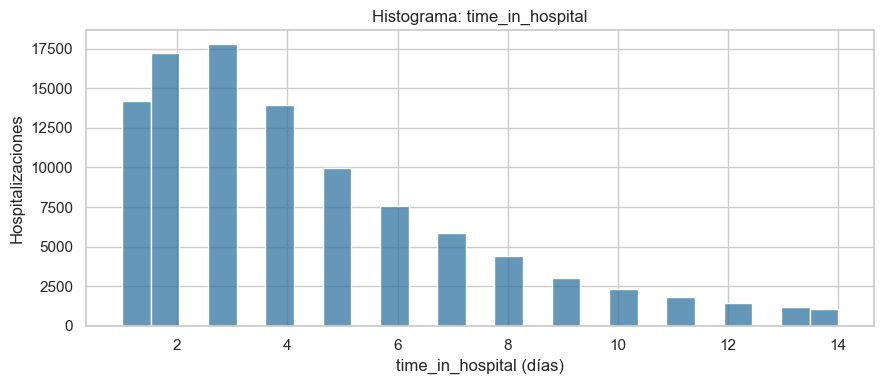

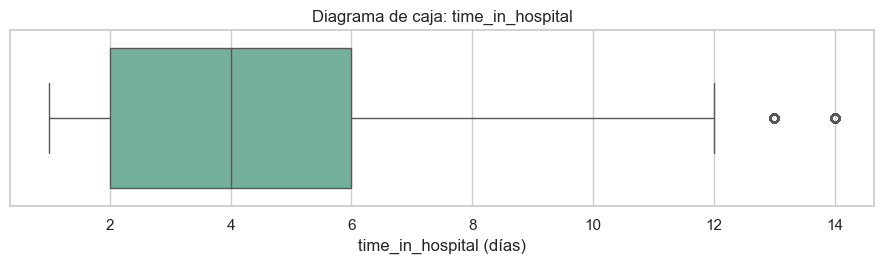

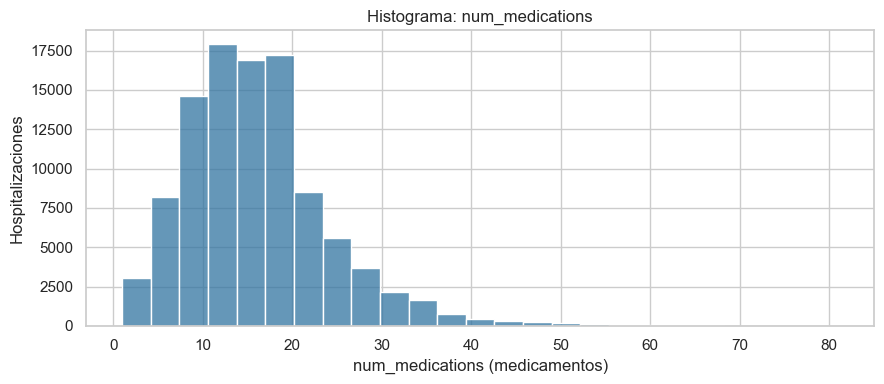

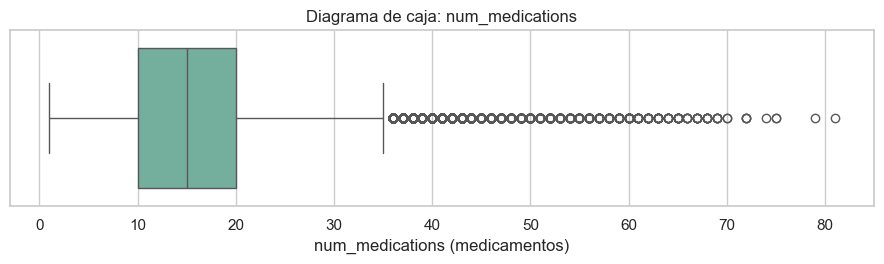

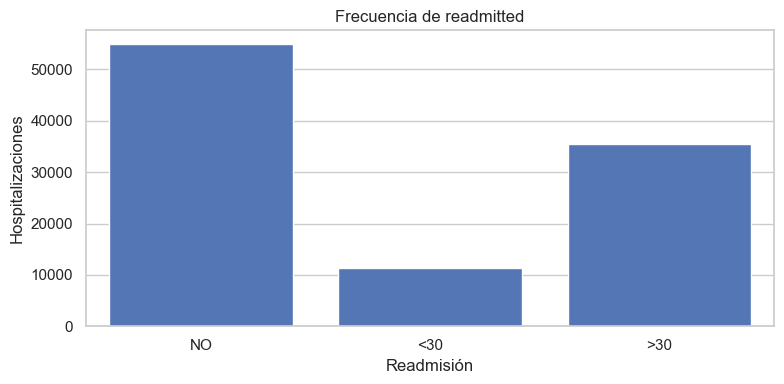

time_in_hospital: mediana=4.00, Q1=2.00, Q3=6.00, media=4.40, máximo=14.00.
num_medications: mediana=15.00, Q1=10.00, Q3=20.00, media=16.02, máximo=81.00.
Categoría más frecuente: NO (53.91% de hospitalizaciones).


In [9]:
sns.set_theme(style='whitegrid')
for var,unidad in [('time_in_hospital','días'),('num_medications','medicamentos')]:
    fig,ax=plt.subplots(figsize=(9,4))
    sns.histplot(medidas[var].dropna(),bins=25,ax=ax,color='#3274a1')
    ax.set(title=f'Histograma: {var}',xlabel=f'{var} ({unidad})',ylabel='Hospitalizaciones')
    plt.tight_layout();plt.show()
    fig,ax=plt.subplots(figsize=(9,2.8))
    sns.boxplot(x=medidas[var],ax=ax,color='#6ab8a0')
    ax.set(title=f'Diagrama de caja: {var}',xlabel=f'{var} ({unidad})')
    plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4))
sns.countplot(data=df,x='readmitted',order=['NO','<30','>30'],ax=ax,color='#4472c4')
ax.set(title='Frecuencia de readmitted',xlabel='Readmisión',ylabel='Hospitalizaciones')
plt.tight_layout();plt.show()
for var in ['time_in_hospital','num_medications']:
    s=medidas[var].dropna();print(f'{var}: mediana={s.median():.2f}, Q1={s.quantile(.25):.2f}, Q3={s.quantile(.75):.2f}, media={s.mean():.2f}, máximo={s.max():.2f}.')
print('Categoría más frecuente:',frecuencias.iloc[0]['readmitted'],f"({frecuencias.iloc[0]['porcentaje']:.2f}% de hospitalizaciones).")

### 3.7 Valores atípicos por rango intercuartílico (IQR)
Regla: se consideran atípicos los valores por debajo de Q1−1,5·IQR o por encima de Q3+1,5·IQR. Es una marca estadística, **no** prueba de error clínico. Se conservan los valores válidos para evitar sesgos y pérdidas de registros.

In [10]:
iqr_resultados=[]
for var in ['time_in_hospital','num_medications']:
    s=medidas[var].dropna();q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    bajo,alto=q1-1.5*iqr,q3+1.5*iqr
    cantidad=int(((s<bajo)|(s>alto)).sum())
    iqr_resultados.append({'variable':var,'Q1':q1,'Q3':q3,'IQR':iqr,'limite_inferior':bajo,'limite_superior':alto,'atipicos':cantidad,'porcentaje':100*cantidad/len(s),'decision':'Conservar; rango plausible, verificar origen antes de excluir'})
display(pd.DataFrame(iqr_resultados).round(3))
pd.DataFrame(iqr_resultados).to_csv('reporte_atipicos_IQR.csv',index=False)

,variable,Q1,Q3,IQR,limite_inferior,limite_superior,atipicos,porcentaje,decision
0,time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252,2.213,"Conservar; rango plausible, verificar origen a..."
1,num_medications,10.0,20.0,10.0,-5.0,35.0,2557,2.513,"Conservar; rango plausible, verificar origen a..."


### 3.8 Detección de *outliers* en las siete variables

Se amplía la detección mediante el criterio IQR a **todas las siete variables cuantitativas**. Se indican los límites, la cantidad y el porcentaje; los valores marcados no se borran automáticamente. Si IQR es cero, se advierte que el método puede marcar valores positivos en variables con muchos ceros y que requiere interpretación clínica/contextual. También se dibujan diagramas de caja con los valores atípicos visibles.

,variable,Q1,Q3,IQR,limite_inferior,limite_superior,outliers,porcentaje,advertencia
0,time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252,2.213,Revisar plausibilidad
1,num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,143,0.141,Revisar plausibilidad
2,num_procedures,0.0,2.0,2.0,-3.0,5.0,4954,4.868,Revisar plausibilidad
3,num_medications,10.0,20.0,10.0,-5.0,35.0,2557,2.513,Revisar plausibilidad
4,number_outpatient,0.0,0.0,0.0,0.0,0.0,16739,16.449,IQR=0; interpretar con cautela
5,number_emergency,0.0,0.0,0.0,0.0,0.0,11383,11.185,IQR=0; interpretar con cautela
6,number_inpatient,0.0,1.0,1.0,-1.5,2.5,7049,6.927,Revisar plausibilidad


Hospitalizaciones con al menos una señal IQR: 34260


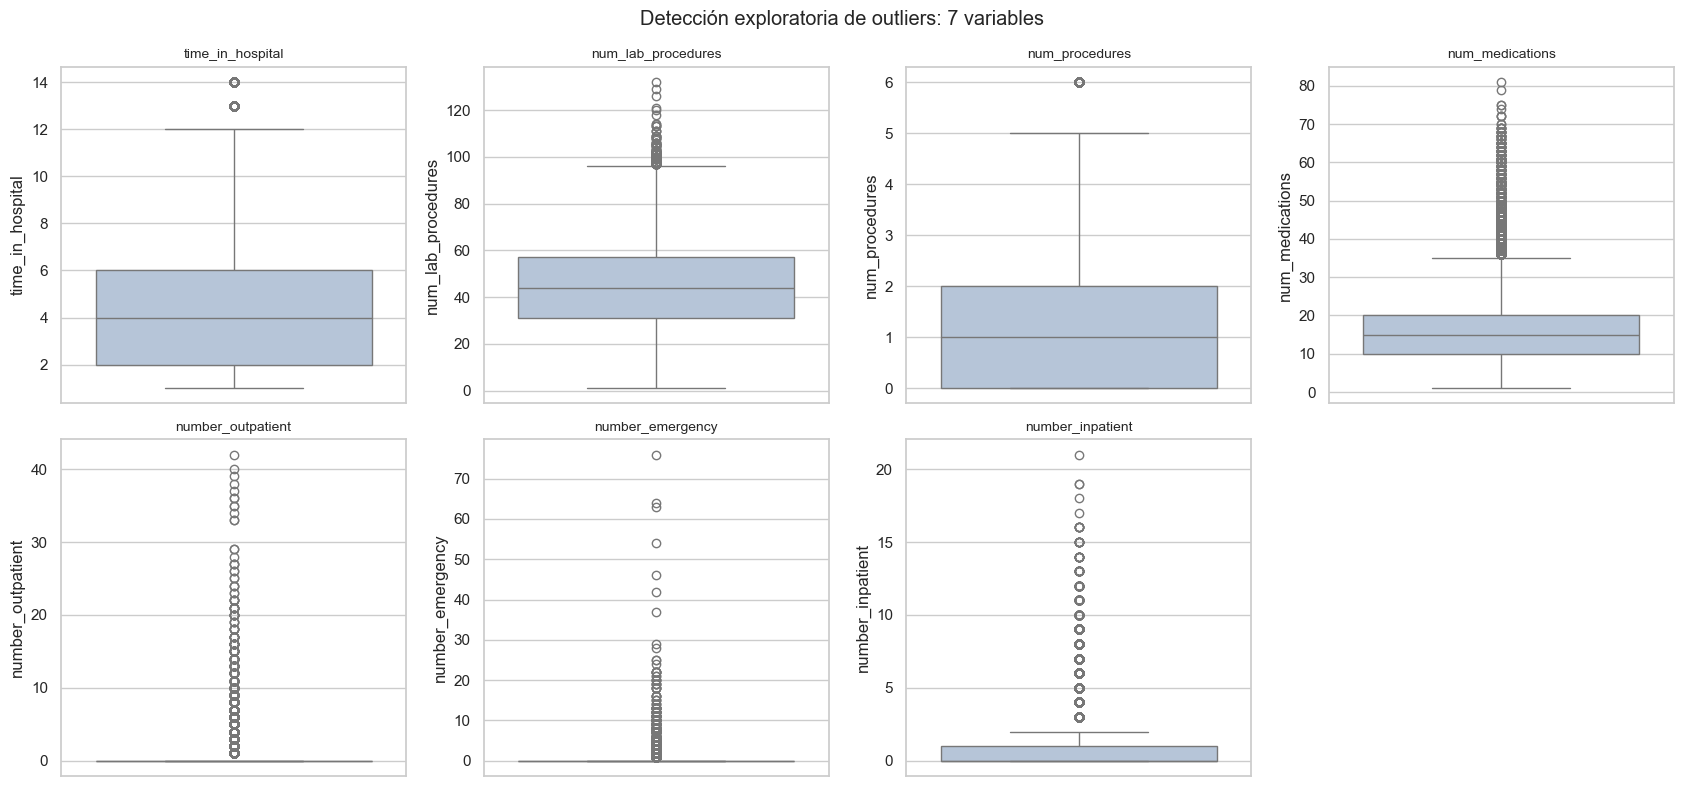

Interpretación: los puntos fuera de bigotes son candidatos a revisión, no errores confirmados.


In [11]:
# Criterio aplicado a las siete variables, sin eliminar registros.
reporte_outliers = []
mascara_outliers = pd.DataFrame(False, index=medidas.index, columns=variables_7)
for variable in variables_7:
    s = medidas[variable].dropna()
    q1, q3 = s.quantile([.25, .75])
    rango_iqr = q3 - q1
    inferior, superior = q1 - 1.5*rango_iqr, q3 + 1.5*rango_iqr
    mascara = ((medidas[variable] < inferior) | (medidas[variable] > superior)).fillna(False)
    mascara_outliers[variable] = mascara
    reporte_outliers.append({
        'variable':variable,'Q1':q1,'Q3':q3,'IQR':rango_iqr,
        'limite_inferior':inferior,'limite_superior':superior,
        'outliers':int(mascara.sum()),'porcentaje':100*mascara.sum()/len(s),
        'advertencia': 'IQR=0; interpretar con cautela' if rango_iqr == 0 else 'Revisar plausibilidad'
    })
reporte_outliers = pd.DataFrame(reporte_outliers)
display(reporte_outliers.round(3))
reporte_outliers.to_csv('reporte_outliers_7_variables.csv', index=False)
print('Hospitalizaciones con al menos una señal IQR:', int(mascara_outliers.any(axis=1).sum()))
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, variable in zip(axes.flat, variables_7):
    sns.boxplot(y=medidas[variable], ax=ax, color='lightsteelblue', showfliers=True)
    ax.set_title(variable, fontsize=10)
for ax in axes.flat[len(variables_7):]: ax.axis('off')
plt.suptitle('Detección exploratoria de outliers: 7 variables')
plt.tight_layout()
plt.show()
print('Interpretación: los puntos fuera de bigotes son candidatos a revisión, no errores confirmados.')

## Paso 4. Fase 3 — Selección y limpieza
**Reglas de tratamiento:** (1) conservar hospitalizaciones individuales, incluidos pacientes repetidos; (2) no modificar ni eliminar categorías `None` de otras variables; (3) comprobar duplicación exacta e identificadores, sin borrado automático; (4) convertir únicamente las siete medidas a tipos numéricos; (5) si hubiera `?`, nulos o conversiones inválidas en alguna de las siete medidas, imputar **la mediana de esa columna** y documentar el número de cambios (sin usar la variable `readmitted`); (6) conservar atípicos plausibles; (7) preservar el índice de fila y exportar archivo de correspondencia con IDs separados. El tamaño antes/después se reporta explícitamente.

In [12]:
trazabilidad=[]
def etapa(etapa,tabla,nota):
    trazabilidad.append({'etapa':etapa,'filas':len(tabla),'columnas':tabla.shape[1],'nota':nota})
etapa('Original descargado',df,'Sin modificaciones')
df_trabajo=df.copy(deep=True)
etapa('Copia de trabajo',df_trabajo,'Conserva todas las filas; no se deduplican pacientes')
# Se convierte a NaN lo no numérico solo en las siete variables seleccionadas.
limpias=df_trabajo[variables_7].replace('?',np.nan).apply(pd.to_numeric,errors='coerce')
etapa('Selección de siete medidas',limpias,'Conversión controlada a numérico')
recuento_imputacion=limpias.isna().sum()
medianas=limpias.median()
assert not medianas.isna().any(), 'No se puede imputar una columna enteramente vacía.'
limpias=limpias.fillna(medianas)
etapa('Imputación por mediana',limpias, f'Valores imputados en las siete variables: {int(recuento_imputacion.sum())}')
assert limpias.notna().all().all()
assert len(limpias)==len(df)
display(pd.DataFrame({'variable':variables_7,'imputaciones':recuento_imputacion.values,'mediana_usada':medianas.values}))
display(pd.DataFrame(trazabilidad))
pd.DataFrame(trazabilidad).to_csv('registro_limpieza.csv',index=False)
limpias.to_csv('datos_numericos_limpios.csv',index=False)
referencia = df[['encounter_id','patient_nbr','readmitted']].copy()
referencia.insert(0,'fila_original_0_based',np.arange(len(df),dtype=int))
referencia.to_csv('correspondencia_registros.csv',index=False)
print('Se preservan',len(limpias),'filas y el orden original.')

,variable,imputaciones,mediana_usada
0,time_in_hospital,0,4.0
1,num_lab_procedures,0,44.0
2,num_procedures,0,1.0
3,num_medications,0,15.0
4,number_outpatient,0,0.0
5,number_emergency,0,0.0
6,number_inpatient,0,0.0


,etapa,filas,columnas,nota
0,Original descargado,101766,50,Sin modificaciones
1,Copia de trabajo,101766,50,Conserva todas las filas; no se deduplican pac...
2,Selección de siete medidas,101766,7,Conversión controlada a numérico
3,Imputación por mediana,101766,7,Valores imputados en las siete variables: 0


Se preservan 101766 filas y el orden original.


### 4.1 Imputación de datos ausentes — comprobación antes y después

Se detectan valores ausentes en las **siete medidas** mediante nulos, `?` y conversiones no numéricas. Se utiliza imputación por **mediana solo cuando existe al menos un dato faltante en una columna**. La mediana se calcula sobre sus valores observados; si una columna no tiene valores válidos, el proceso se detiene en lugar de inventar datos. La variable `readmitted` y los identificadores no se imputan ni se escalan. Los faltantes de columnas no seleccionadas quedan documentados, sin modificar la base original.

**Razón:** la mediana es menos sensible a extremos que la media. La imputación mantiene el número de hospitalizaciones, pero puede concentrar observaciones en el valor central; por eso queda registrada.

In [13]:
# Comprobación explícita de imputación: no se atribuyen faltantes inexistentes.
antes_imputar = df_trabajo[variables_7].replace('?', np.nan).apply(pd.to_numeric, errors='coerce')
resumen_imputacion = pd.DataFrame({
    'variable': variables_7,
    'ausentes_antes': antes_imputar.isna().sum().reindex(variables_7).to_numpy(),
    'porcentaje_antes': (antes_imputar.isna().mean()*100).reindex(variables_7).to_numpy(),
    'metodo': ['Mediana' if antes_imputar[v].isna().any() else 'No necesario' for v in variables_7],
    'mediana_observada': antes_imputar.median().reindex(variables_7).to_numpy(),
    'ausentes_despues': limpias.isna().sum().reindex(variables_7).to_numpy()
})
resumen_imputacion['valores_imputados'] = resumen_imputacion['ausentes_antes'] - resumen_imputacion['ausentes_despues']
display(resumen_imputacion)
resumen_imputacion.to_csv('reporte_imputacion.csv', index=False)
assert (resumen_imputacion['ausentes_despues']==0).all()
assert (resumen_imputacion['valores_imputados']==resumen_imputacion['ausentes_antes']).all()
print('Total ausentes antes:', int(resumen_imputacion['ausentes_antes'].sum()))
print('Total imputaciones:', int(resumen_imputacion['valores_imputados'].sum()))
if resumen_imputacion['ausentes_antes'].sum() == 0:
    print('En estas 7 variables NO había datos ausentes: no se sustituyó ningún valor.')
else:
    print('Se imputaron únicamente las celdas ausentes mediante la mediana de su columna.')
# Evaluación por fila: los datos observados se preservan idénticos.
for v in variables_7:
    observadas = antes_imputar[v].notna()
    assert np.allclose(antes_imputar.loc[observadas,v],limpias.loc[observadas,v])
print('Verificado: los valores originales no ausentes permanecen sin cambios.')

,variable,ausentes_antes,porcentaje_antes,metodo,mediana_observada,ausentes_despues,valores_imputados
0,time_in_hospital,0,0.0,No necesario,4.0,0,0
1,num_lab_procedures,0,0.0,No necesario,44.0,0,0
2,num_procedures,0,0.0,No necesario,1.0,0,0
3,num_medications,0,0.0,No necesario,15.0,0,0
4,number_outpatient,0,0.0,No necesario,0.0,0,0
5,number_emergency,0,0.0,No necesario,0.0,0,0
6,number_inpatient,0,0.0,No necesario,0.0,0,0


Total ausentes antes: 0
Total imputaciones: 0
En estas 7 variables NO había datos ausentes: no se sustituyó ningún valor.
Verificado: los valores originales no ausentes permanecen sin cambios.


## Paso 5. Variables cuantitativas seleccionadas
Las siete medidas representan días, procedimientos, medicamentos o visitas **contables**. `encounter_id` y `patient_nbr` son identificadores; los tres códigos de admisión/alta son categorías; `age` es un intervalo ordinal, no una medición continua. `readmitted` se conserva para describir, pero **no** se escala.

In [14]:
display(pd.DataFrame({'variable':variables_7,'tipo_final':limpias.dtypes.astype(str).values,'faltantes_finales':limpias.isna().sum().values}))

,variable,tipo_final,faltantes_finales
0,time_in_hospital,int64,0
1,num_lab_procedures,int64,0
2,num_procedures,int64,0
3,num_medications,int64,0
4,number_outpatient,int64,0
5,number_emergency,int64,0
6,number_inpatient,int64,0


## Paso 6. Normalización Min-Max
Para una columna no constante: $x_{norm}=(x-\min(x))/(\max(x)-\min(x))$. Con `MinMaxScaler`, una variable constante se transforma en cero al usar rango [0,1]; no se divide manualmente entre cero. Valores extremos pueden comprimir el resto de observaciones.

In [15]:
minmax=MinMaxScaler(feature_range=(0,1))
normalizados=pd.DataFrame(minmax.fit_transform(limpias.copy()),columns=variables_7,index=limpias.index)
display(normalizados.head(10))
tabla_minmax=pd.DataFrame({'min_antes':limpias.min(),'max_antes':limpias.max(),'min_despues':normalizados.min(),'max_despues':normalizados.max()})
display(tabla_minmax)
assert normalizados.ge(-1e-10).all().all() and normalizados.le(1+1e-10).all().all()
for c in variables_7:
    if limpias[c].nunique()>1:
        assert np.isclose(normalizados[c].min(),0,atol=1e-10)
        assert np.isclose(normalizados[c].max(),1,atol=1e-10)
    else:
        assert np.allclose(normalizados[c],0,atol=1e-10)
print('Comprobación Min-Max: todas las columnas dentro de [0,1].')

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000


,min_antes,max_antes,min_despues,max_despues
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


Comprobación Min-Max: todas las columnas dentro de [0,1].


## Paso 7. Estandarización Z-score
Para cada variable no constante: $z=(x-\mu)/\sigma$. `StandardScaler` usa la desviación estándar **poblacional** (`ddof=0`); una columna constante se transforma en cero y mantiene desviación cero. Las puntuaciones negativas están por debajo de la media; Z-score no limita los datos a [0,1].

In [16]:
zscaler=StandardScaler()
estandarizados=pd.DataFrame(zscaler.fit_transform(limpias.copy()),columns=variables_7,index=limpias.index)
display(estandarizados.head(10))
validacion_z=pd.DataFrame({'media_z':estandarizados.mean(),'desviacion_z_ddof0':estandarizados.std(ddof=0),'constante_original':limpias.nunique().eq(1)})
display(validacion_z)
assert np.allclose(estandarizados.mean(),0,atol=1e-10)
for c in variables_7:
    esperado=0 if limpias[c].nunique()==1 else 1
    assert np.isclose(estandarizados[c].std(ddof=0),esperado,atol=1e-10)
print('Comprobación Z-score: medias ≈ 0 y desviaciones ≈ 1 (0 en constantes).')

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276


,media_z,desviacion_z_ddof0,constante_original
time_in_hospital,5.809126e-17,1.0,False
num_lab_procedures,1.161825e-16,1.0,False
num_procedures,-6.479410e-17,1.0,False
num_medications,-1.340568e-16,1.0,False
number_outpatient,3.574847e-17,1.0,False
number_emergency,1.787424e-17,1.0,False
number_inpatient,-3.574847e-17,1.0,False


Comprobación Z-score: medias ≈ 0 y desviaciones ≈ 1 (0 en constantes).


## Paso 8. Comparación estadística, visual, cálculo manual y exportación
Las transformaciones son lineales crecientes por columna cuando existe variación, así que preservan el orden y la forma relativa de la distribución. La normalización restringe al intervalo [0,1]; la estandarización centra en 0 y expresa desviaciones estándar. Ninguna de las dos corrige una distribución asimétrica.

In [17]:
def estad_tabla(datos,nombre):
    salida=pd.DataFrame({'min':datos.min(),'max':datos.max(),'media':datos.mean(),'desv_ddof0':datos.std(ddof=0)})
    salida.insert(0,'version',nombre)
    salida.index.name='variable'
    return salida.reset_index()
comparacion=pd.concat([estad_tabla(limpias,'original_limpia'),estad_tabla(normalizados,'minmax_0_1'),estad_tabla(estandarizados,'zscore')],ignore_index=True)
display(comparacion.round(4))
comparacion.to_csv('comparacion_estadistica.csv',index=False)

,variable,version,min,max,media,desv_ddof0
0,time_in_hospital,original_limpia,1.0000,14.0000,4.3960,2.9851
1,num_lab_procedures,original_limpia,1.0000,132.0000,43.0956,19.6743
2,num_procedures,original_limpia,0.0000,6.0000,1.3397,1.7058
3,num_medications,original_limpia,1.0000,81.0000,16.0218,8.1275
4,number_outpatient,original_limpia,0.0000,42.0000,0.3694,1.2673
5,number_emergency,original_limpia,0.0000,76.0000,0.1978,0.9305
6,number_inpatient,original_limpia,0.0000,21.0000,0.6356,1.2629
7,time_in_hospital,minmax_0_1,0.0000,1.0000,0.2612,0.2296
8,num_lab_procedures,minmax_0_1,0.0000,1.0000,0.3213,0.1502
9,num_procedures,minmax_0_1,0.0000,1.0000,0.2233,0.2843


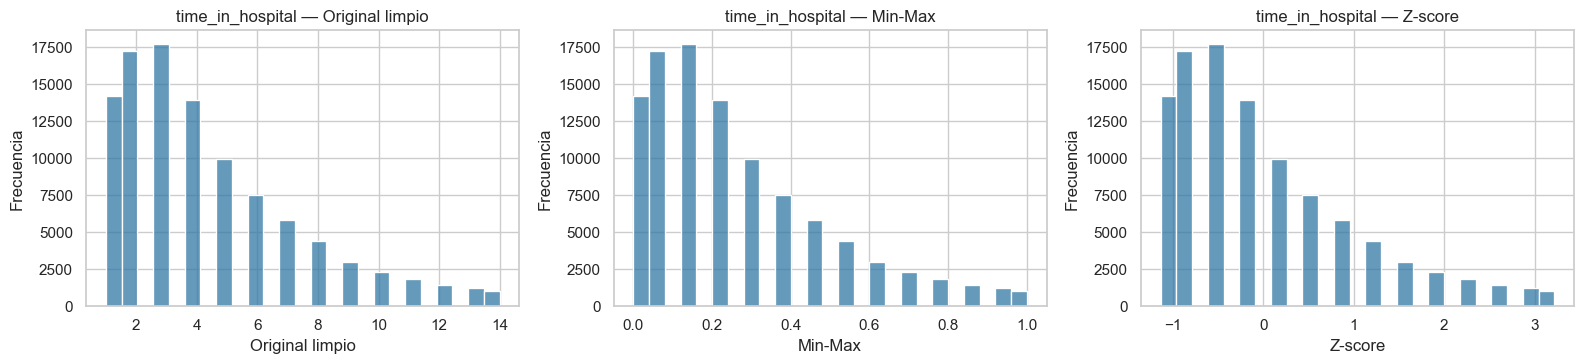

Interpretación time_in_hospital: se mantienen el orden y la forma del histograma; cambian las unidades del eje horizontal.


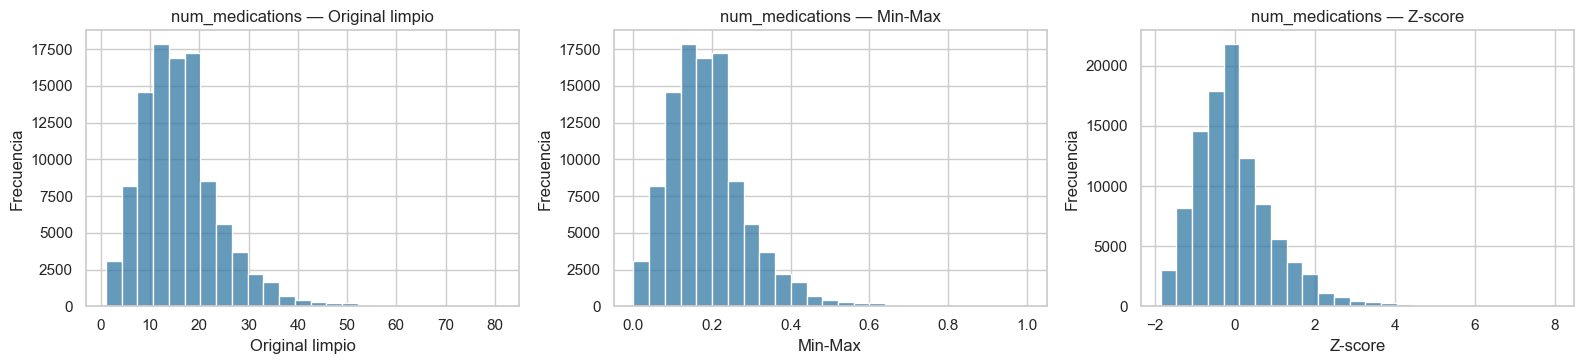

Interpretación num_medications: se mantienen el orden y la forma del histograma; cambian las unidades del eje horizontal.


In [18]:
for variable in ['time_in_hospital','num_medications']:
    series=[('Original limpio',limpias[variable]),('Min-Max',normalizados[variable]),('Z-score',estandarizados[variable])]
    fig,axs=plt.subplots(1,3,figsize=(16,3.8))
    for ax,(etiqueta,s) in zip(axs,series):
        sns.histplot(s,bins=25,ax=ax,color='#3178a5')
        ax.set(title=f'{variable} — {etiqueta}',xlabel=etiqueta,ylabel='Frecuencia')
    plt.tight_layout();plt.show()
    print(f'Interpretación {variable}: se mantienen el orden y la forma del histograma; cambian las unidades del eje horizontal.')

### Cálculo manual comprobado sobre cinco hospitalizaciones
Se toman las primeras cinco filas de `time_in_hospital` (se eligen por posición, no por conveniencia). Los cálculos manuales emplean los mismos parámetros ajustados por Python y se contrastan fila por fila.

In [ ]:
variable='time_in_hospital'
xmin=float(limpias[variable].min());xmax=float(limpias[variable].max())
mu=float(limpias[variable].mean());sigma=float(limpias[variable].std(ddof=0))
print(f'Parámetros para {variable}: mínimo={xmin:.6f}, máximo={xmax:.6f}, media={mu:.6f}, desviación ddof=0={sigma:.6f}')
seleccion=limpias[variable].iloc[:5]
manual_minmax=(seleccion-xmin)/(xmax-xmin) if xmax!=xmin else seleccion*0
manual_z=(seleccion-mu)/sigma if sigma!=0 else seleccion*0
calculos=pd.DataFrame({'fila_original_0_based':seleccion.index,'valor_original':seleccion.values,
                       'minmax_manual':manual_minmax.values,'minmax_sklearn':normalizados.loc[seleccion.index,variable].values,
                       'z_manual':manual_z.values,'z_sklearn':estandarizados.loc[seleccion.index,variable].values})
display(calculos.round(8))
assert np.allclose(calculos['minmax_manual'],calculos['minmax_sklearn'])
assert np.allclose(calculos['z_manual'],calculos['z_sklearn'])
print('Comprobado: los cinco cálculos manuales coinciden con scikit-learn.')

In [ ]:
assert list(limpias.columns)==list(normalizados.columns)==list(estandarizados.columns)
assert limpias.index.equals(normalizados.index) and limpias.index.equals(estandarizados.index)
assert len(normalizados)==len(estandarizados)==len(df)
normalizados.to_csv('datos_normalizados.csv',index=False)
estandarizados.to_csv('datos_estandarizados.csv',index=False)
print('Exportados: datos_normalizados.csv, datos_estandarizados.csv, comparacion_estadistica.csv y correspondencia_registros.csv.')
print('Correspondencia: la fila k de ambos CSV (desde 0, sin contar la cabecera) equivale a fila_original_0_based=k en correspondencia_registros.csv.')
# Confirmación de lectura de los archivos creados.
a=pd.read_csv('datos_normalizados.csv'); b=pd.read_csv('datos_estandarizados.csv')
assert a.shape==b.shape==(len(df),7)
print('CSV verificados:',a.shape,b.shape)

## Resumen integrado de las cuatro técnicas

1. **Detección de faltantes:** se contabilizan nulos y `?`; la categoría `None` no se interpreta automáticamente como ausencia.
2. **Imputación:** mediana solo para celdas ausentes entre las siete variables seleccionadas; se comparan conteos antes y después.
3. **Outliers:** límites IQR de las siete variables, cantidades, porcentajes y gráficos; se conservan los valores plausibles.
4. **Normalización:** MinMaxScaler sobre una copia limpia independiente; rango comprobado [0,1].
5. **Estandarización:** StandardScaler sobre otra copia limpia independiente; media cercana a 0 y desviación poblacional cercana a 1.

**Orden de ejecución:** cargar → evaluar calidad → detectar outliers → convertir/imputar → obtener dos versiones independientes del mismo conjunto limpio → verificar → exportar. No se crean datos artificiales ni se entrenan modelos.

In [ ]:
# Cuadro final que concentra controles verificables del ejercicio.
resumen_tecnicas = pd.DataFrame([
    {'tecnica':'Imputación de ausentes','resultado':f"{int(resumen_imputacion['valores_imputados'].sum())} valores imputados", 'verificacion':bool(limpias.notna().all().all())},
    {'tecnica':'Detección de outliers (IQR)','resultado':f"{int(mascara_outliers.any(axis=1).sum())} filas marcadas (sin excluir)", 'verificacion':len(mascara_outliers)==len(df)},
    {'tecnica':'Normalización Min-Max','resultado':'Valores entre 0 y 1', 'verificacion':bool(normalizados.ge(-1e-10).all().all() and normalizados.le(1+1e-10).all().all())},
    {'tecnica':'Estandarización Z-score','resultado':'Media 0 y desviación poblacional 1 (salvo constantes)', 'verificacion':bool(np.allclose(estandarizados.mean(),0,atol=1e-10))}
])
display(resumen_tecnicas)
assert resumen_tecnicas['verificacion'].all()
resumen_tecnicas.to_csv('resumen_cuatro_tecnicas.csv',index=False)

## Conclusiones

**Pregunta 1: distribución y hospitalización.** Los histogramas, diagramas de caja y la tabla exploratoria permiten identificar rangos, tendencia central, asimetría y extremos del tiempo de estancia y los medicamentos. La interpretación concreta debe basarse en las cifras impresas por las celdas de análisis, no en suposiciones.

**Pregunta 2: readmisiones y utilización asistencial.** El gráfico de barras y `frecuencias` ofrecen la proporción observada de `NO`, `<30` y `>30`. La asociación descriptiva entre readmisión y medidas puede explorarse mediante la siguiente tabla agregada; no es evidencia causal.

In [ ]:
descriptivo_readmision = pd.concat([df[['readmitted']],limpias[['time_in_hospital','num_medications','number_inpatient']]],axis=1).groupby('readmitted',dropna=False).agg(['count','mean','median'])
display(descriptivo_readmision.round(2))
print('Interpretación: comparar medias y medianas entre categorías sin asumir causalidad ni extrapolar a pacientes individuales.')

**Elección de transformación.** Min-Max conviene cuando interesa una escala acotada [0,1] pero es sensible a extremos. Z-score conviene para expresar diferencias respecto de la media en unidades de desviación estándar; tampoco elimina por sí solo el efecto de valores extremos.

**Limitaciones.** Son hospitalizaciones históricas de una población seleccionada; un mismo paciente puede aparecer varias veces. La imputación, si se requirió, sustituye valores desconocidos sin recuperar su valor real. Las transformaciones no corrigen sesgos de origen, asimetría ni causalidad. Las conclusiones son académicas, no clínicas.

**CRISP-DM:** se completan las fases 1 y 2 y la fase 3 hasta selección, limpieza y escalamiento. No se entrenan ni evalúan modelos.

## Preguntas de reflexión

**1. ¿Por qué un código categórico numérico no debe escalarse como una medición?** Porque los valores representan etiquetas; por ejemplo, una categoría `3` no implica ser tres veces una categoría `1`, ni necesariamente una distancia cuantitativa interpretable.

**2. ¿Cómo afectaría un extremo a Min-Max y a Z-score?** En Min-Max, un máximo muy elevado puede comprimir la mayoría de datos cerca de cero. En Z-score, un valor extremo puede desplazar la media y aumentar la desviación estándar, alterando los valores estandarizados del resto.

**3. ¿Por qué una readmisión del mismo paciente no es un duplicado?** Porque son encuentros distintos en fechas o circunstancias diferentes. `patient_nbr` puede repetirse mientras `encounter_id` identifica hospitalizaciones individuales.

**4. ¿Qué diferencia hay entre cambiar de escala y corregir una distribución asimétrica?** Min-Max y Z-score aplican transformaciones lineales que mantienen la asimetría relativa y el orden; corregir asimetría exige transformaciones distintas, como logaritmos cuando son pertinentes y justificables.

**5. ¿Cómo evitar la fuga de información al entrenar un modelo?** Separar primero entrenamiento y prueba, idealmente agrupando por `patient_nbr` para que un mismo paciente no aparezca en ambos; ajustar imputadores y escaladores **solo** con entrenamiento, y aplicar a validación/prueba con parámetros ya aprendidos. También verificar que ninguna variable incluya información conocida únicamente después del evento objetivo.

## Referencias y declaración de asistencia

- Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J
- UCI Machine Learning Repository. Ficha y diccionario de variables: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008
- scikit-learn. Documentación de `MinMaxScaler`: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html
- scikit-learn. Documentación de `StandardScaler`: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

